<a href="https://colab.research.google.com/github/ST10286777/DASC_A2_Q7/blob/main/Q7_ClaudeGenerated.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

# =====================================================================
# TASK 1: LOAD THE DATASET
# =====================================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# ---------- OPTION A: upload the CSV from your device (default) ----------
from google.colab import files
uploaded = files.upload()              # a file picker appears; choose School_Data_CSV.csv
file_name = list(uploaded.keys())[0]   # use whatever name Colab saved it as

Saving School_Data_CSV.csv to School_Data_CSV.csv


In [2]:

# South African data often contains accented characters, so a UTF-8 read can
# fail with UnicodeDecodeError. We try UTF-8 first and fall back to latin-1.
try:
    df_raw = pd.read_csv(file_name, encoding="utf-8", low_memory=False)
except UnicodeDecodeError:
    df_raw = pd.read_csv(file_name, encoding="latin-1", low_memory=False)

# low_memory=False makes pandas read the whole file before guessing dtypes.
# Without it, a column can be split into chunks with different guessed types
# (a "DtypeWarning: mixed types") which later breaks numeric plotting.

print("Shape (rows, columns):", df_raw.shape)
display(df_raw.head())
print("\nColumn names:\n", list(df_raw.columns))
print("\nDtypes as loaded:\n", df_raw.dtypes)
print("\nMissing values per column:\n", df_raw.isna().sum())


Shape (rows, columns): (199853, 9)


,emisno,centername,institution_name,centreno,quintile,ward_id,street_address,new_long,new_lat
0,200100005,ABERDEEN SECONDARY SCHOOL (20),ABERDEEN SECONDARY SCHOOL,4201001,3,21001001,"10 PARLIAMENT STREET, ABERDEEN, 6270",24.06183,-32.47385
1,200100012,ADELAIDE GYMNASIUM,ADELAIDE GYMNASIUM,4171044,4,21208001,"WELSH STREET, ADELAIDE, 5760",26.29476,-32.71036
2,200100018,AEROVILLE(SOMERSET EAST) (20),AEROVILLE SECONDARY SCHOOL,4201002,3,21002002,"PERSEVERANCE DR, SOMERSET EAST, 5850",25.60073,-32.74592
3,200100019,Al Azhar Institute,AL-AZHAR PRIMARY SCHOOL,4222001,NOT APPLICABLE,29500009,"42 RUDOLPH STREET, MALABAR, PORT ELIZABETH, 6000",25.53563,-33.91924
4,200100021,ALEXANDER ROAD HIGH SCHOOL,ALEXANDER ROAD HIGH SCHOOL,4221002,5,29300007,"ALEXANDER ROAD, NEWTON PARK, PORT ELIZABETH, 6055",25.57181,-33.94147



Column names:
 ['emisno', 'centername', 'institution_name', 'centreno', 'quintile', 'ward_id', 'street_address', 'new_long', 'new_lat']

Dtypes as loaded:
 emisno               object
centername           object
institution_name     object
centreno             object
quintile             object
ward_id              object
street_address       object
new_long             object
new_lat             float64
dtype: object

Missing values per column:
 emisno                   0
centername            5931
institution_name     65927
centreno                30
quintile              2813
ward_id                782
street_address        6703
new_long             32112
new_lat             115746
dtype: int64


In [5]:
# =====================================================================
# TASK 2: DATA CLEANING
# Order: copy -> tidy text -> deduplicate -> type conversion ->
#        validate/outliers -> missing value imputation
# =====================================================================
df = df_raw.copy()   # never modify the raw data; lets you re-run cleaning safely

# Define the column name constants mapping to your specific dataset columns
QUINTILE_COL = 'quintile'
WARD_COL = 'ward_id'
LON_COL = 'new_long'
LAT_COL = 'new_lat'

# ---- 2.0 Tidy column names and text values -------------------------
df.columns = df.columns.str.strip()
for c in df.select_dtypes(include="object").columns:
    df[c] = df[c].astype(str).str.strip()
    # astype(str) turns real NaN into the text "nan"; convert those back,
    # otherwise they are not counted as missing and become fake categories.
    df[c] = df[c].replace({"nan": np.nan, "NaN": np.nan, "": np.nan,
                           "NA": np.nan, "N/A": np.nan, "None": np.nan})

# ---- 2.1 Deduplication ---------------------------------------------
before = len(df)
df = df.drop_duplicates()   # removes rows identical in EVERY column
print(f"Exact duplicates removed: {before - len(df)}")
# If the dataset has a school identifier (e.g. a EMIS / school code column),
# also deduplicate on it, since one school should appear only once:
# df = df.drop_duplicates(subset=["<school_id_column>"], keep="first")

# ---- 2.2 Type conversion -------------------------------------------
# QUINTILE: often stored as text ("Quintile 1", "1", "No Fee", "Q3").
# Extract the digit, then convert to a nullable integer.
df[QUINTILE_COL] = (
    df[QUINTILE_COL].astype(str).str.extract(r"([1-5])")[0]
    .pipe(pd.to_numeric, errors="coerce")   # anything unparseable -> NaN, not a crash
    .astype("Int64")                        # capital-I Int64 can hold NaN (plain int cannot)
)

# LAT/LONG: if stored as text (or with comma decimals "-29,85") they will not
# plot properly. Replace commas then coerce to float.
for c in (LAT_COL, LON_COL):
    df[c] = pd.to_numeric(df[c].astype(str).str.replace(",", ".", regex=False),
                          errors="coerce")

# WARD: it is a LABEL, not a quantity. Even if it is numeric (e.g. 59500001)
# keep it as text so no code treats it as a number to average or scale.
df[WARD_COL] = df[WARD_COL].astype(str).str.replace(r"\.0$", "", regex=True)
df.loc[df[WARD_COL].isin(["nan", "None"]), WARD_COL] = np.nan

print("\nDtypes after conversion:\n", df[[QUINTILE_COL, WARD_COL, LAT_COL, LON_COL]].dtypes)

# ---- 2.3 Outlier treatment -----------------------------------------
# (a) Coordinates: a statistical IQR rule is WRONG here (schools legitimately
#     span the whole country). Use domain knowledge: South Africa lies roughly
#     between lat -35 to -22 and long 16 to 33. Values outside (0, 0 "null island",
#     swapped lat/long, typos) are invalid -> set to NaN so they can be treated.
SA_LAT, SA_LON = (-35.0, -22.0), (16.0, 33.5)
bad_coord = ~df[LAT_COL].between(*SA_LAT) | ~df[LON_COL].between(*SA_LON)
bad_coord &= df[[LAT_COL, LON_COL]].notna().all(axis=1)   # missing is handled later
print(f"Coordinates outside South Africa's bounding box: {bad_coord.sum()}")
df.loc[bad_coord, [LAT_COL, LON_COL]] = np.nan

# (b) Quintile: valid range is 1-5; anything else is an error, not an outlier.
df.loc[~df[QUINTILE_COL].isin([1, 2, 3, 4, 5]), QUINTILE_COL] = pd.NA

# (c) Any OTHER genuinely numeric columns (e.g. learner counts, if present):
#     cap at 1.5*IQR (winsorising) instead of deleting rows.
skip = {QUINTILE_COL, LAT_COL, LON_COL}
for c in df.select_dtypes(include=[np.number]).columns:
    if c in skip or df[c].nunique() < 10:     # skip IDs/codes/low-cardinality
        continue
    q1, q3 = df[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((df[c] < low) | (df[c] > high)).sum()
    if n_out:
        print(f"Capping {n_out} outliers in '{c}' to [{low:.2f}, {high:.2f}]")
        df[c] = df[c].clip(low, high)

# ---- 2.4 Missing value imputation ----------------------------------
print("\nMissing values BEFORE imputation:\n", df.isna().sum()[df.isna().sum() > 0])

# Categorical columns -> "Unknown" (keeps the row, makes the gap visible).
for c in df.select_dtypes(include="object").columns:
    df[c] = df[c].fillna("Unknown")

# Quintile is ordinal, so use the MODE (most common level), not the mean (a
# mean of 2.7 is not a valid quintile). Imputing invents data, so also keep
# a flag recording which rows were filled.
df["quintile_imputed"] = df[QUINTILE_COL].isna()
df[QUINTILE_COL] = df[QUINTILE_COL].fillna(df[QUINTILE_COL].mode()[0])

# Coordinates: fill with the median of the school's own ward (a sensible local
# estimate), and DROP rows with no ward information either. Imputed points are
# approximations -- say so in your report.
df["coords_imputed"] = df[LAT_COL].isna() | df[LON_COL].isna()
for c in (LAT_COL, LON_COL):
    df[c] = df[c].fillna(df.groupby(WARD_COL)[c].transform("median"))
df = df.dropna(subset=[LAT_COL, LON_COL]).reset_index(drop=True)

print("\nMissing values AFTER imputation:\n", df.isna().sum()[df.isna().sum() > 0])
print("Final shape:", df.shape)
display(df.describe(include="all").T.head(15))

Exact duplicates removed: 799

Dtypes after conversion:
 quintile      Int64
ward_id      object
new_lat     float64
new_long    float64
dtype: object
Coordinates outside South Africa's bounding box: 15

Missing values BEFORE imputation:
 centername            5931
institution_name     65448
centreno                16
quintile             41883
ward_id                767
street_address        6684
new_long             39368
new_lat             115433
dtype: int64

Missing values AFTER imputation:
 Series([], dtype: int64)
Final shape: (193927, 11)


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
emisno,193927,33519,99,1550,NaN,NaN,NaN,NaN,NaN,NaN,NaN
centername,193927,11868,NOT APPLICABLE,89242,NaN,NaN,NaN,NaN,NaN,NaN,NaN
institution_name,193927,50295,Unknown,65438,NaN,NaN,NaN,NaN,NaN,NaN,NaN
centreno,193927,10350,99,94667,NaN,NaN,NaN,NaN,NaN,NaN,NaN
quintile,193927.0,<NA>,<NA>,<NA>,2.036189,1.231545,1.0,1.0,2.0,3.0,5.0
ward_id,193927,4684,TO BE UPDATED,12041,NaN,NaN,NaN,NaN,NaN,NaN,NaN
street_address,193927,51020,Unknown,6683,NaN,NaN,NaN,NaN,NaN,NaN,NaN
new_long,193927.0,NaN,NaN,NaN,-61.820639,16233.036081,-2950000.0,26.97182,28.75263,30.35671,118.677419
new_lat,193927.0,NaN,NaN,NaN,-28.611592,3.072645,-34.821641,-30.7724,-28.6149,-26.200868,-22.19481
quintile_imputed,193927,2,False,153776,NaN,NaN,NaN,NaN,NaN,NaN,NaN


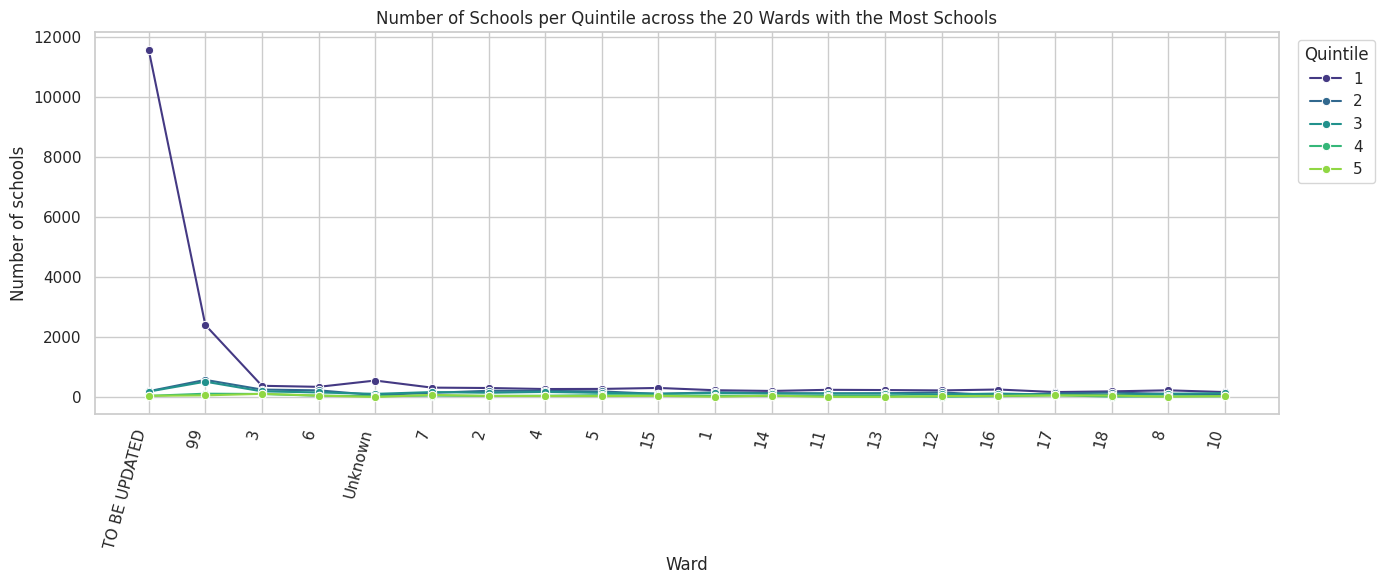

In [7]:
#=====================================================================
# TASK 3: LINE PLOT - NUMBER OF SCHOOLS PER QUINTILE ACROSS WARDS
# =====================================================================
# PROBLEMS TO BE AWARE OF (datatype related):
#  1. A line plot joins points in order, implying the x-axis is continuous or
#     ordered. Wards are unordered categories, so the line between two wards
#     has no real meaning. It is used here because the task asks for it;
#     a grouped bar chart is the statistically cleaner alternative.
#  2. If WARD is a number (e.g. 59500001) matplotlib treats it as a continuous
#     axis, spacing wards by numeric distance and leaving huge gaps. Because
#     we converted wards to strings, each ward becomes an evenly spaced tick.
#  3. If QUINTILE is numeric, seaborn's hue uses a continuous gradient legend.
#     Casting it to string/category gives 5 distinct lines and a clean legend.
#  4. There may be hundreds of wards. Plotting all of them produces an
#     unreadable plot, so we show the TOP_N wards with the most schools.
#  5. Missing combinations (a ward with no Quintile 5 school) show as NaN, which
#     breaks the line. We fill them with 0 using crosstab.

TOP_N = 20
top_wards = df[WARD_COL].value_counts().head(TOP_N).index

counts = (
    pd.crosstab(df[WARD_COL], df[QUINTILE_COL].astype(str))   # rows=wards, cols=quintiles
    .loc[top_wards]                                           # keep the busiest wards
    .reset_index()
    .melt(id_vars=WARD_COL, var_name="Quintile", value_name="School_Count")  # long format for seaborn
)

plt.figure(figsize=(14, 6))
sns.lineplot(data=counts, x=WARD_COL, y="School_Count", hue="Quintile",
             hue_order=["1", "2", "3", "4", "5"], marker="o", palette="viridis")
plt.title(f"Number of Schools per Quintile across the {TOP_N} Wards with the Most Schools")
plt.xlabel("Ward")
plt.ylabel("Number of schools")
plt.xticks(rotation=75, ha="right")
plt.legend(title="Quintile", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.show()


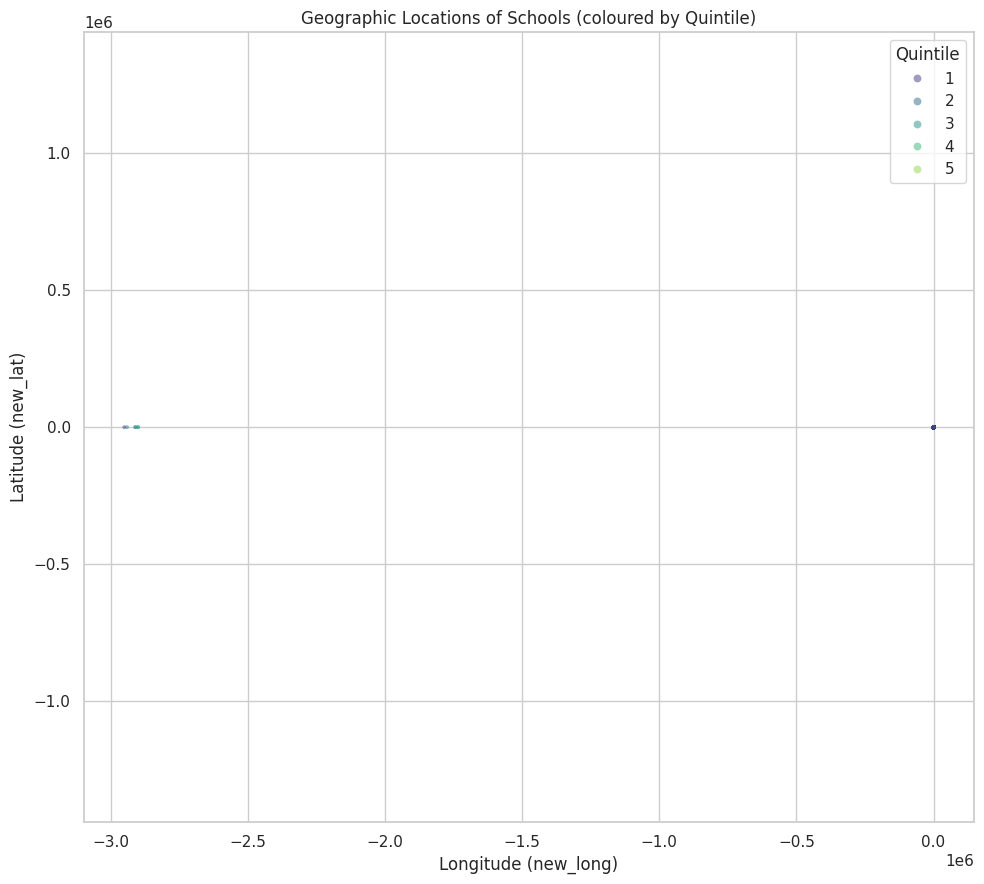

In [9]:
# =====================================================================
# TASK 4: SCATTER PLOT - GEOGRAPHIC LOCATION OF SCHOOLS
# =====================================================================
# PROBLEMS TO BE AWARE OF:
#  1. If new_lat / new_long were read as text (object dtype), matplotlib plots
#     the strings as categories: every unique value becomes a tick label,
#     nothing looks like a map, and it is extremely slow. We converted them
#     to float in Task 2.
#  2. Unreplaced bad values such as 0,0 or swapped lat/long stretch the axes
#     and squash all real schools into one corner. We removed them in Task 2.
#  3. NaN coordinates are silently skipped by matplotlib, so the plot can
#     look fine while schools are missing. We checked for this above.
#  4. Longitude is X and latitude is Y. Swapping them mirrors/rotates the map.
#  5. Thousands of overlapping points hide density, so we use small markers
#     and transparency (alpha).
#  6. This is NOT a real map projection. Lat/long plotted on a flat grid is
#     slightly distorted; set_aspect("equal") limits this.

plt.figure(figsize=(10, 9))
sns.scatterplot(data=df, x=LON_COL, y=LAT_COL,
                hue=df[QUINTILE_COL].astype(str),            # colour by quintile (categorical)
                hue_order=["1", "2", "3", "4", "5"],
                palette="viridis", s=8, alpha=0.5, linewidth=0)
plt.title("Geographic Locations of Schools (coloured by Quintile)")
plt.xlabel("Longitude (new_long)")
plt.ylabel("Latitude (new_lat)")
plt.gca().set_aspect("equal", adjustable="datalim")
plt.legend(title="Quintile", markerscale=2)
plt.tight_layout()
plt.show()

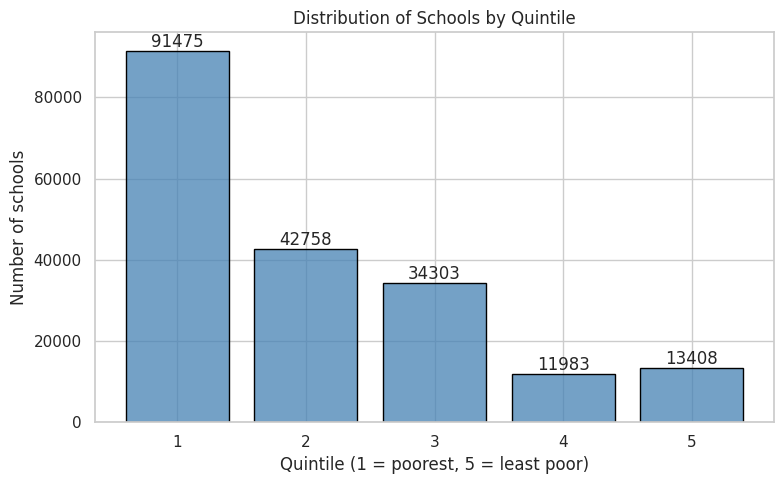

quintile
1    91475
2    42758
3    34303
4    11983
5    13408
Name: count, dtype: int64


In [10]:
# =====================================================================
# TASK 5: HISTOGRAM - DISTRIBUTION OF SCHOOLS BY QUINTILE
# =====================================================================
# PROBLEMS TO BE AWARE OF:
#  1. Quintile is ORDINAL/DISCRETE (1-5), not continuous. A default histogram
#     chooses bins automatically (e.g. 10 bins from 1 to 5), so bars can
#     straddle two quintiles or leave gaps and misrepresent the counts.
#     Fix: discrete=True, which centres one bar on each integer.
#  2. If the column is text ("1", "2", ...) histplot treats it as categories
#     and orders them alphabetically, which breaks with values like
#     "Quintile 10" or "No Fee". We converted it to integers in Task 2.
#  3. If NaNs remain, they are silently dropped and the totals look too low.
#  4. If the column is a pandas Int64 (nullable) dtype, some older
#     matplotlib/seaborn versions error. Casting to int after imputation
#     (done below) avoids that.

quint = df[QUINTILE_COL].astype(int)

plt.figure(figsize=(8, 5))
ax = sns.histplot(x=quint, discrete=True, shrink=0.8, color="steelblue", edgecolor="black")
ax.set_xticks([1, 2, 3, 4, 5])
for p in ax.patches:                                   # label each bar with its count
    ax.annotate(f"{int(p.get_height())}", (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom")
plt.title("Distribution of Schools by Quintile")
plt.xlabel("Quintile (1 = poorest, 5 = least poor)")
plt.ylabel("Number of schools")
plt.tight_layout()
plt.show()

print(quint.value_counts().sort_index())